# Facebook Ads Project - Click Prediction

**Goal:** predict whether a user will click on a Facebook ad (`Clicked` = 1) using:
- `Time Spent on Site` (minutes)
- `Salary` (yearly)

**Plan:**
1. Load & inspect the data
2. EDA (Exploratory Data Analysis) with many visualizations
3. Preprocessing
4. Train several models: Logistic Regression, KNN (K-Nearest Neighbors), Decision Tree, Random Forest, SVM (Support Vector Machine), Naive Bayes
5. Compare models and pick the highest accuracy
6. Save the best model with `pickle` to use it in the Streamlit app (`app.py`)

### 1. Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

### 2. Loading & inspecting data

In [2]:
df = pd.read_csv('facebook_ads.csv', encoding="ISO-8859-1")
df.head()

,Names,emails,Country,Time Spent on Site,Salary,Clicked
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,25.649648,55330.06006,0
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,32.456107,79049.07674,1
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,20.945978,41098.60826,0
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,54.039325,37143.35536,1
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,34.249729,37355.11276,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 499 entries, 0 to 498
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Names               499 non-null    str    
 1   emails              499 non-null    str    
 2   Country             499 non-null    str    
 3   Time Spent on Site  499 non-null    float64
 4   Salary              499 non-null    float64
 5   Clicked             499 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 48.2 KB


In [4]:
df.describe().round(2)

,Time Spent on Site,Salary,Clicked
count,499.00,499.00,499.0
mean,32.92,52896.99,0.5
std,9.10,18989.18,0.5
min,5.00,20.00,0.0
25%,26.43,38888.12,0.0
50%,33.20,52840.91,1.0
75%,39.11,65837.29,1.0
max,60.00,100000.00,1.0


In [5]:
# Check missing values and duplicated rows
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicated rows:', df.duplicated().sum())

Missing values per column:
Names                 0
emails                0
Country               0
Time Spent on Site    0
Salary                0
Clicked               0
dtype: int64

Duplicated rows: 0


In [6]:
# How balanced is the target column?
df['Clicked'].value_counts(normalize=True).round(3)

Clicked
1    0.501
0    0.499
Name: proportion, dtype: float64

## 3. EDA (Exploratory Data Analysis)

We make a copy of the data just for plotting, where `Clicked` is text ("Yes" / "No")
so the colors in the charts are clear.

In [7]:
df_plot = df.copy()
df_plot['Clicked'] = df_plot['Clicked'].map({0: 'No', 1: 'Yes'})

color_map = {'No': '#636EFA', 'Yes': '#EF553B'}

#### 3.1 Target distribution

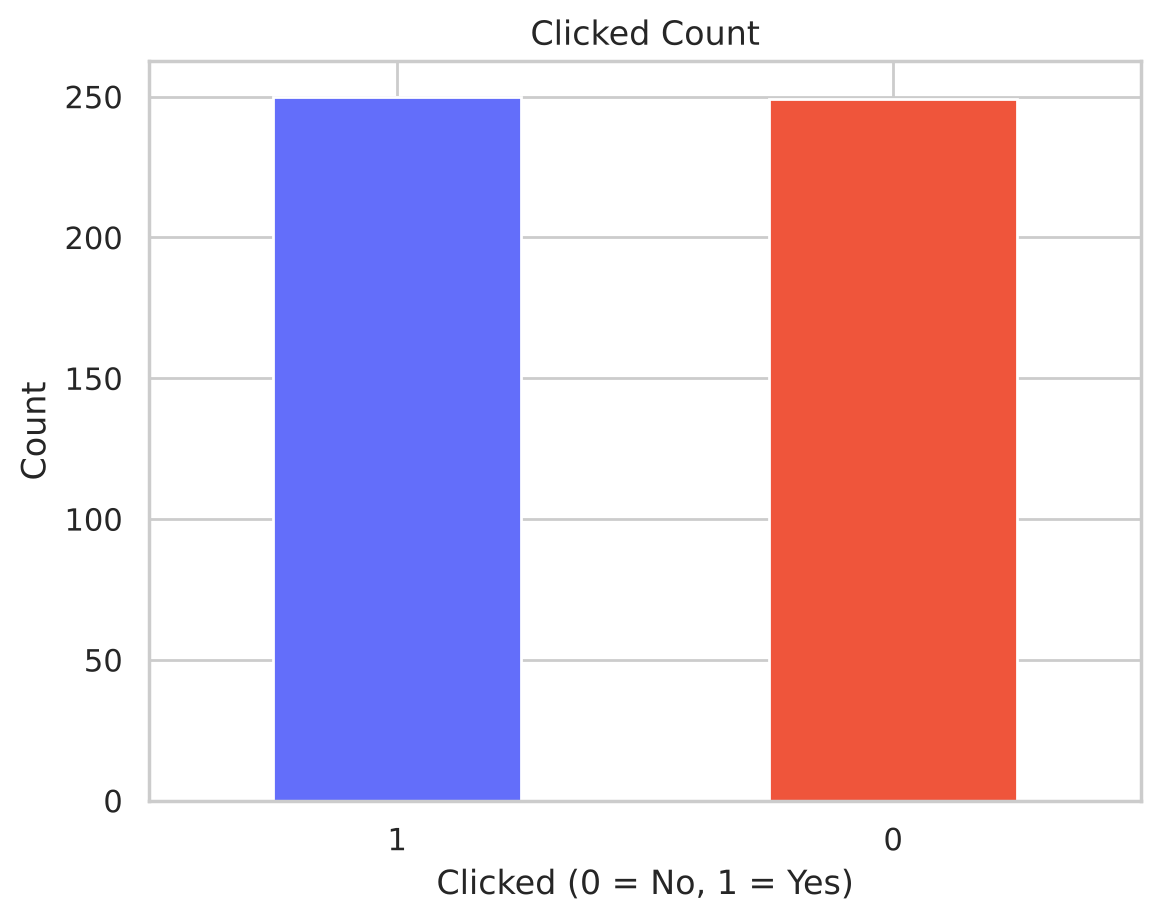

In [8]:
df['Clicked'].value_counts().plot(kind='bar', color=['#636EFA', '#EF553B'])
plt.title('Clicked Count')
plt.xlabel('Clicked (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [9]:
counts = df_plot['Clicked'].value_counts()

fig = px.pie(values=counts.values, names=counts.index, title='Clicked Percentage',
             color=counts.index, color_discrete_map=color_map, hole=0.4)
fig.show()

#### 3.2 Distribution of each feature

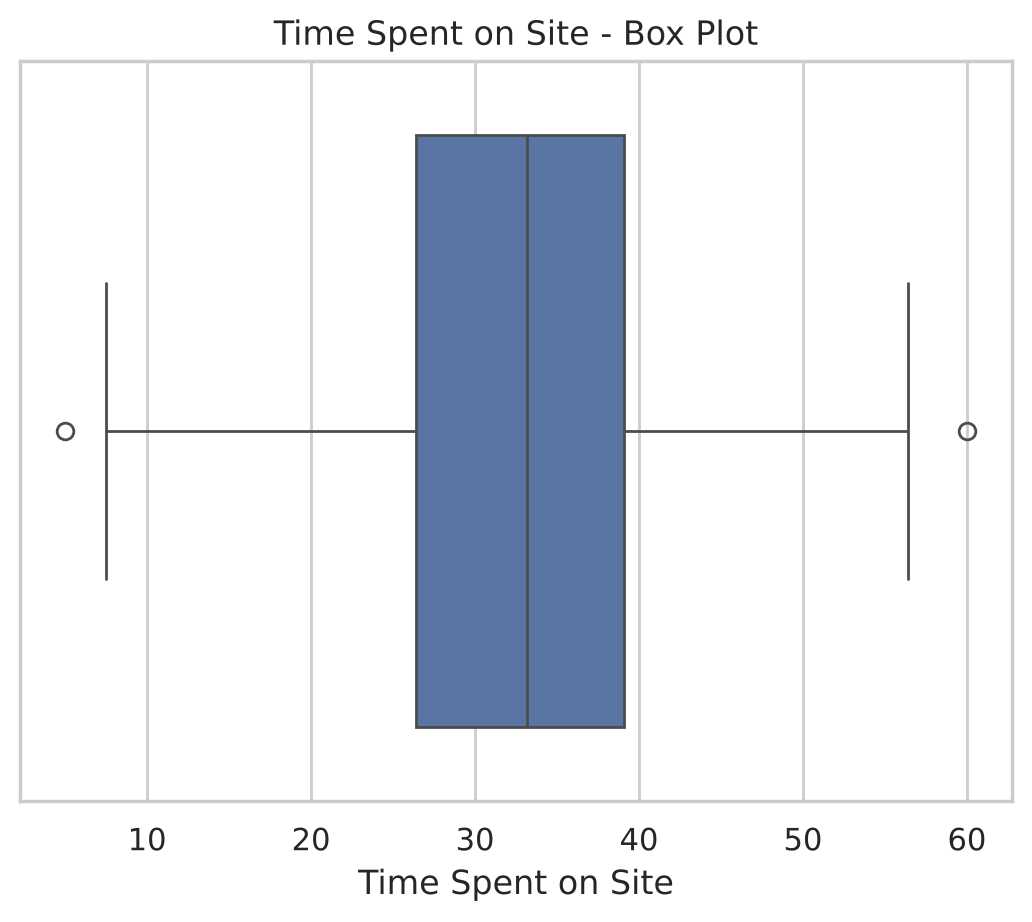

In [10]:
sns.boxplot(data=df, x='Time Spent on Site')
plt.title('Time Spent on Site - Box Plot')
plt.show()

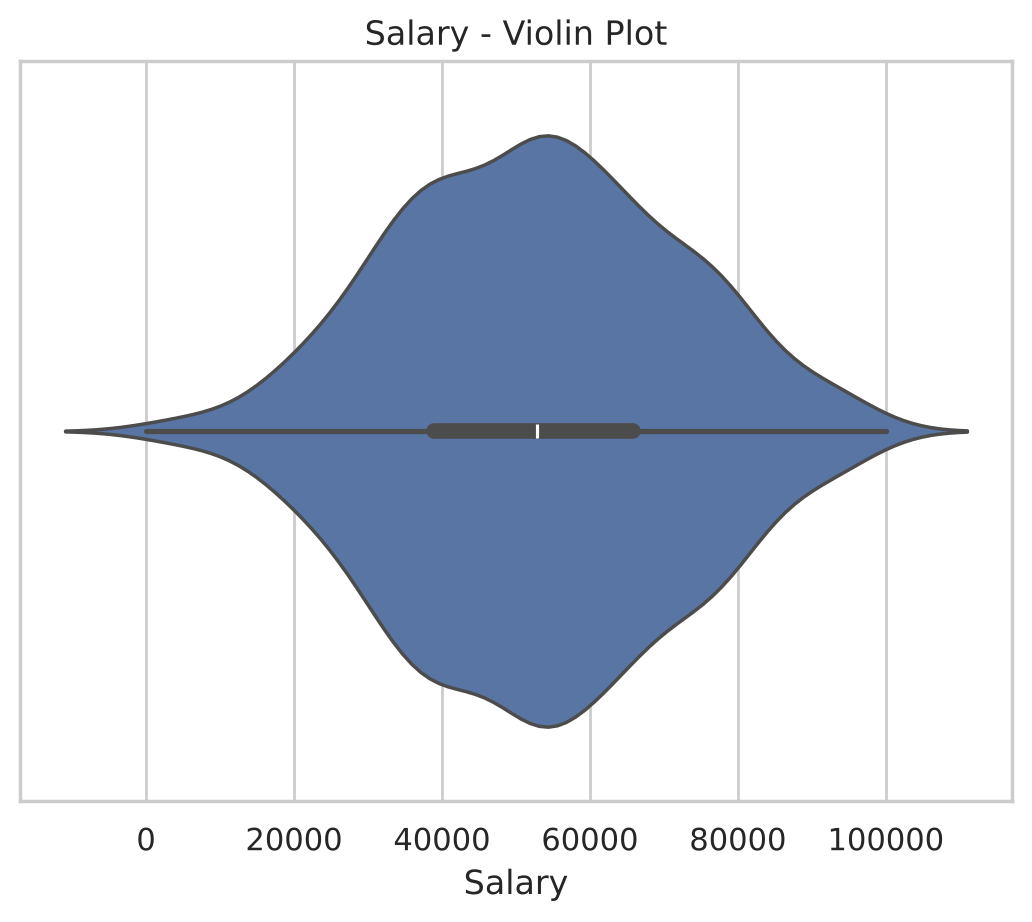

In [11]:
sns.violinplot(data=df, x='Salary')
plt.title('Salary - Violin Plot')
plt.show()

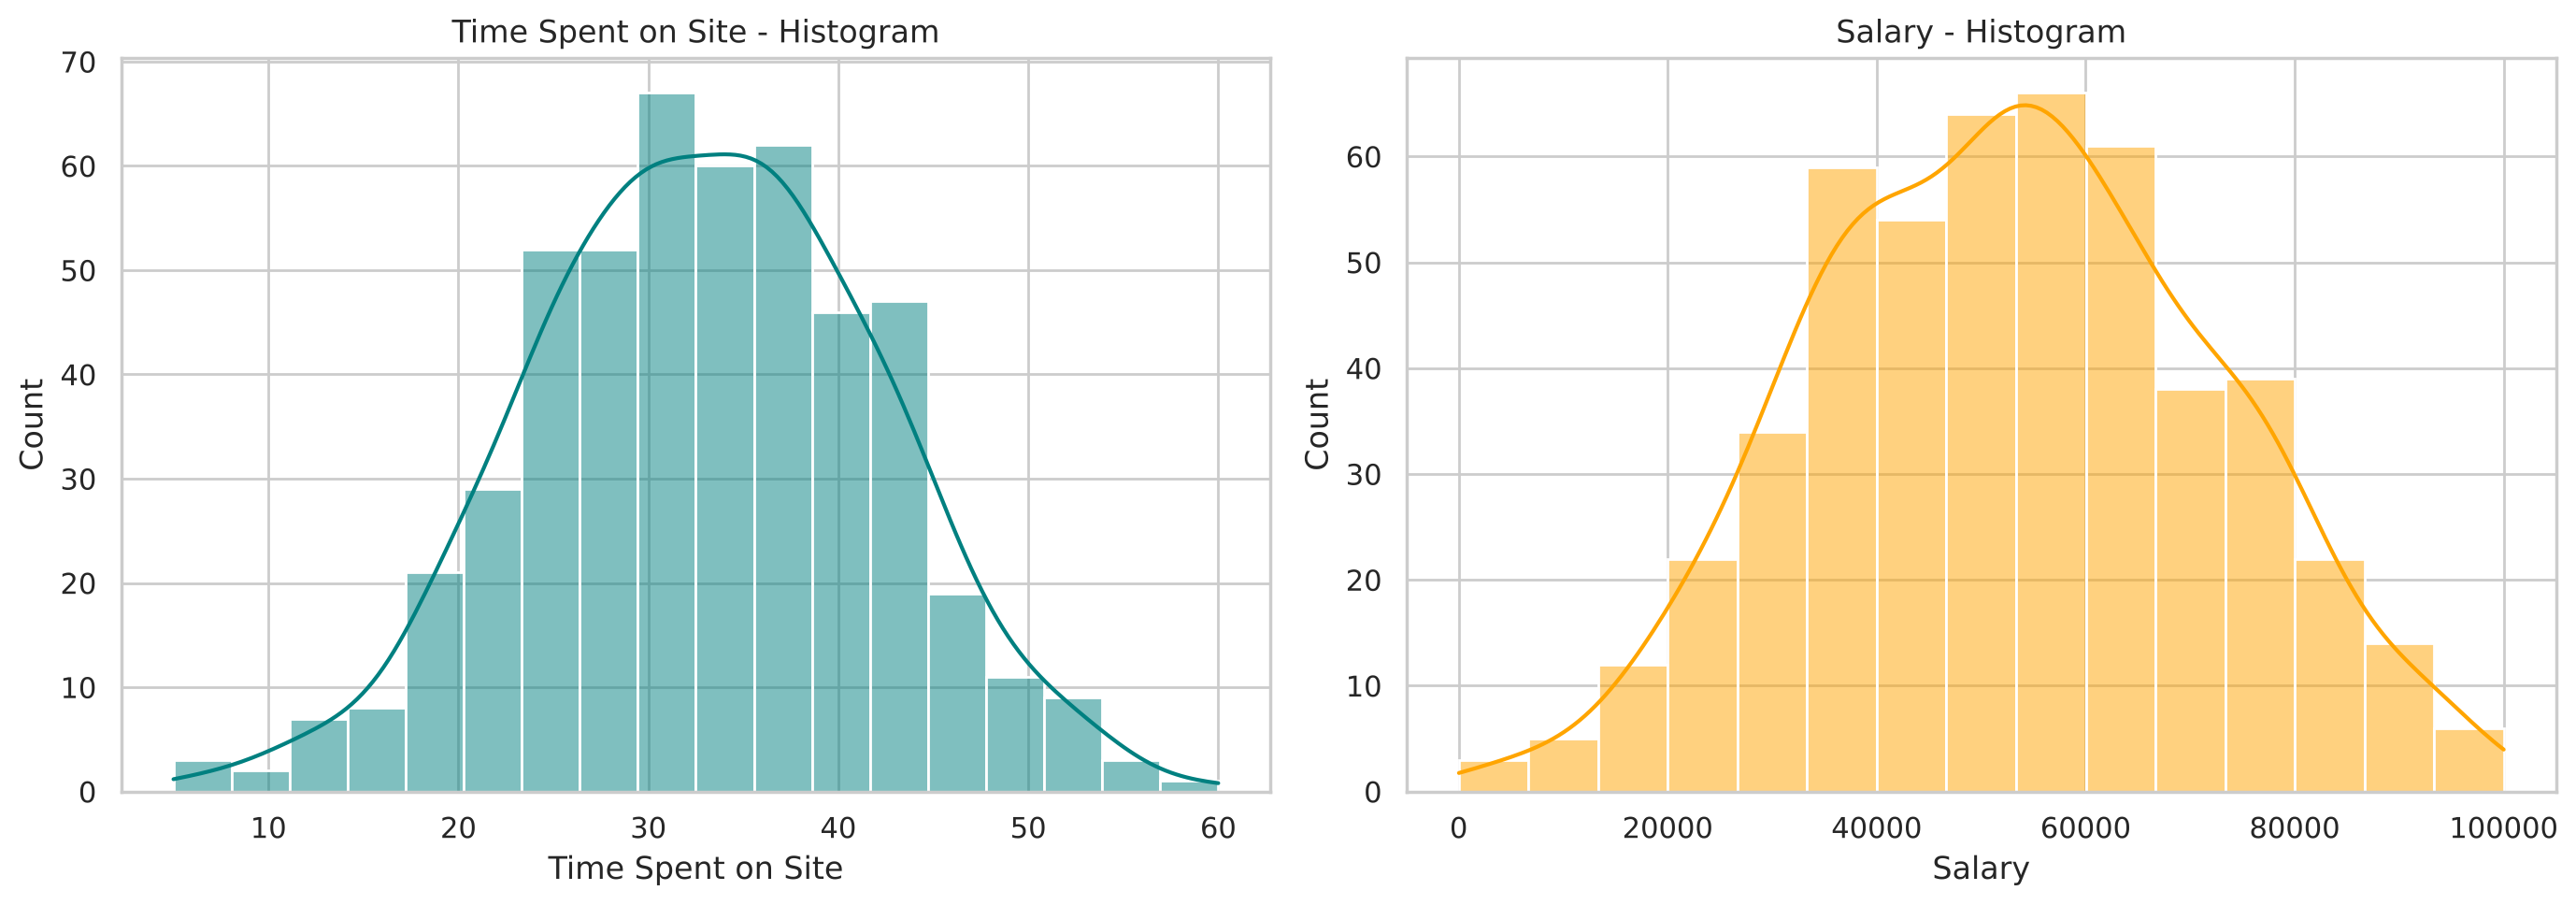

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df, x='Time Spent on Site', kde=True, ax=axes[0], color='teal')
axes[0].set_title('Time Spent on Site - Histogram')

sns.histplot(data=df, x='Salary', kde=True, ax=axes[1], color='orange')
axes[1].set_title('Salary - Histogram')

plt.tight_layout()
plt.show()

#### 3.3 Features vs target

In [13]:
fig = px.histogram(df_plot, x='Time Spent on Site', color='Clicked', marginal='box',
                   barmode='overlay', opacity=0.7, color_discrete_map=color_map,
                   title='Time Spent on Site by Clicked')
fig.show()

In [14]:
fig = px.histogram(df_plot, x='Salary', color='Clicked', marginal='box',
                   barmode='overlay', opacity=0.7, color_discrete_map=color_map,
                   title='Salary by Clicked')
fig.show()

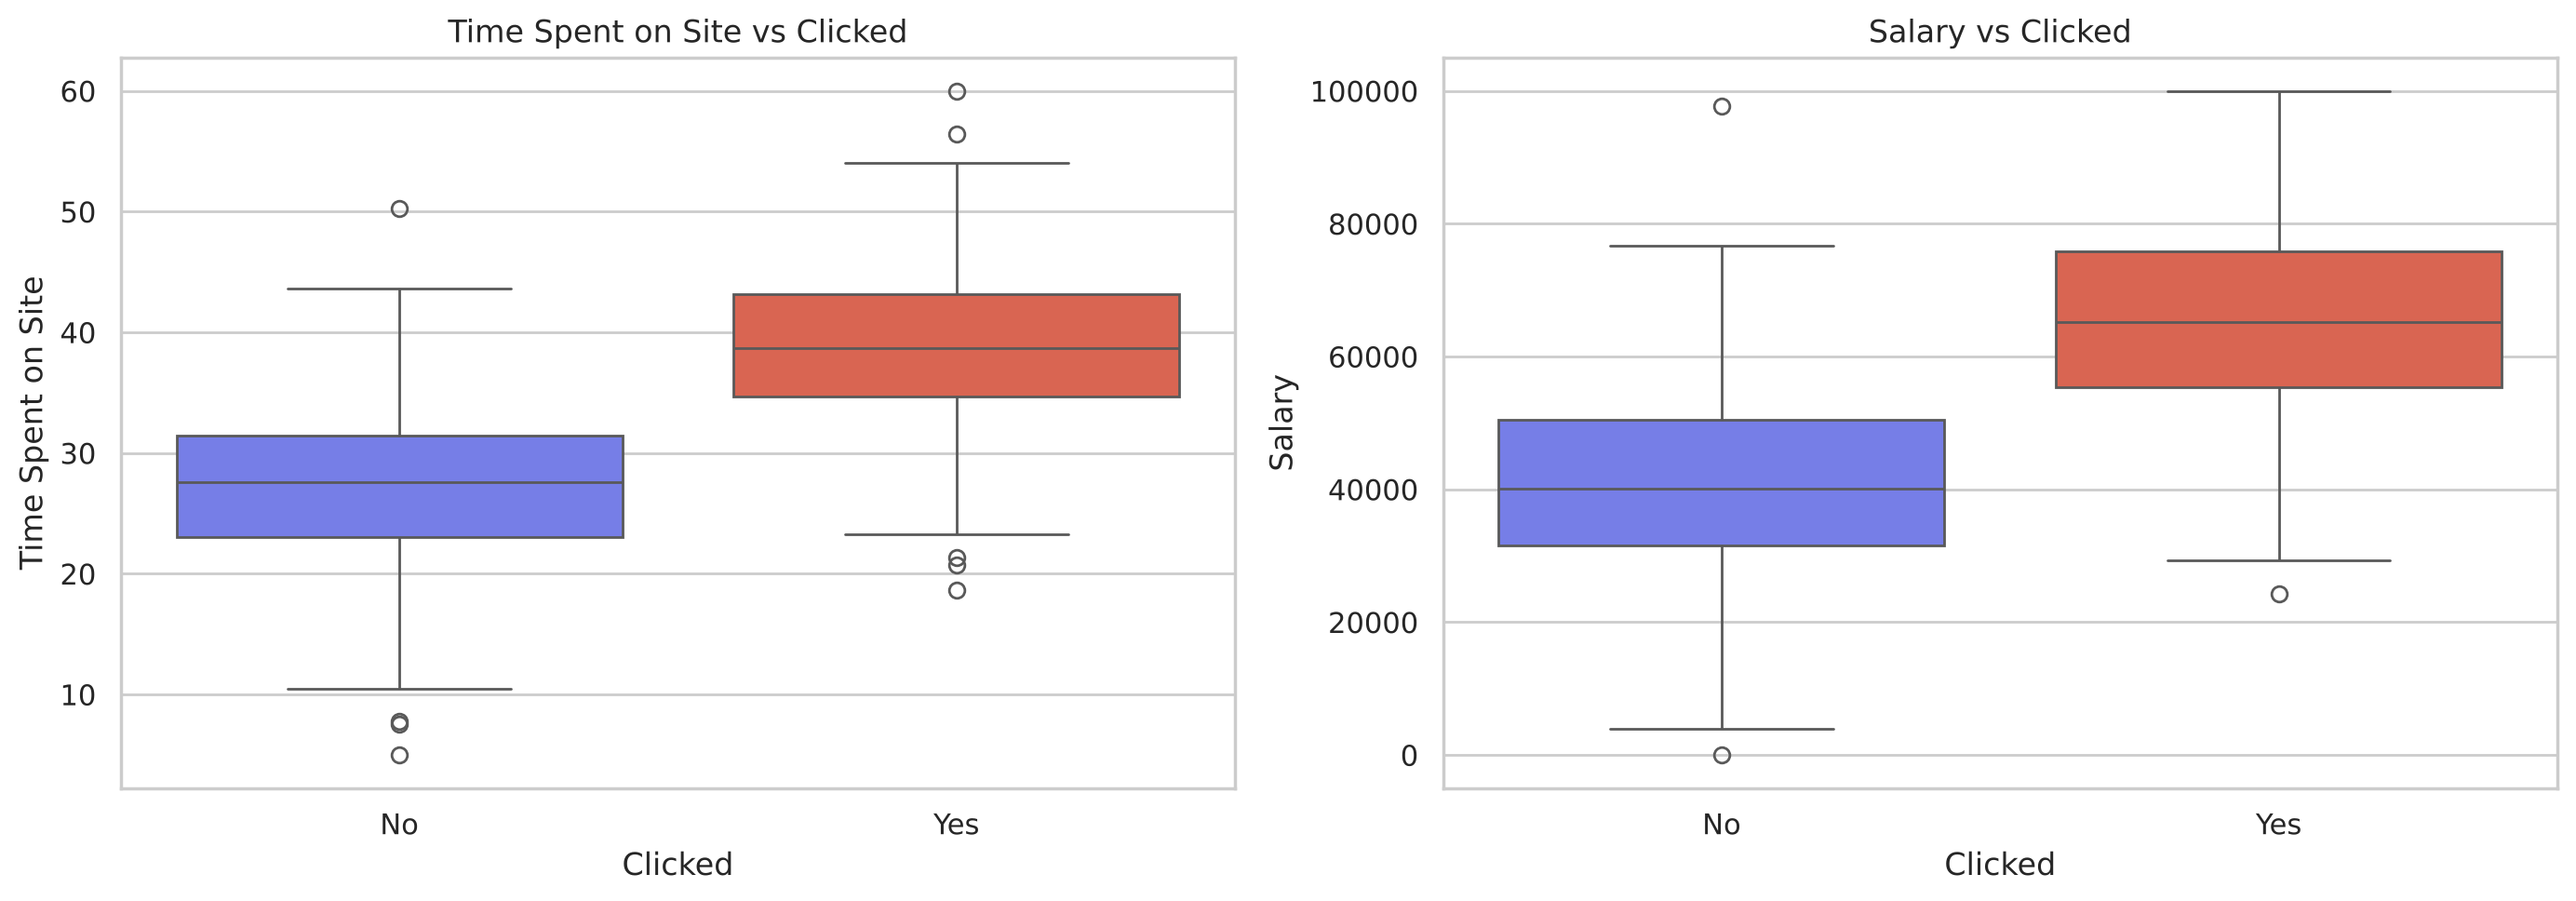

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_plot, x='Clicked', y='Time Spent on Site', ax=axes[0], palette=color_map)
axes[0].set_title('Time Spent on Site vs Clicked')

sns.boxplot(data=df_plot, x='Clicked', y='Salary', ax=axes[1], palette=color_map)
axes[1].set_title('Salary vs Clicked')

plt.tight_layout()
plt.show()

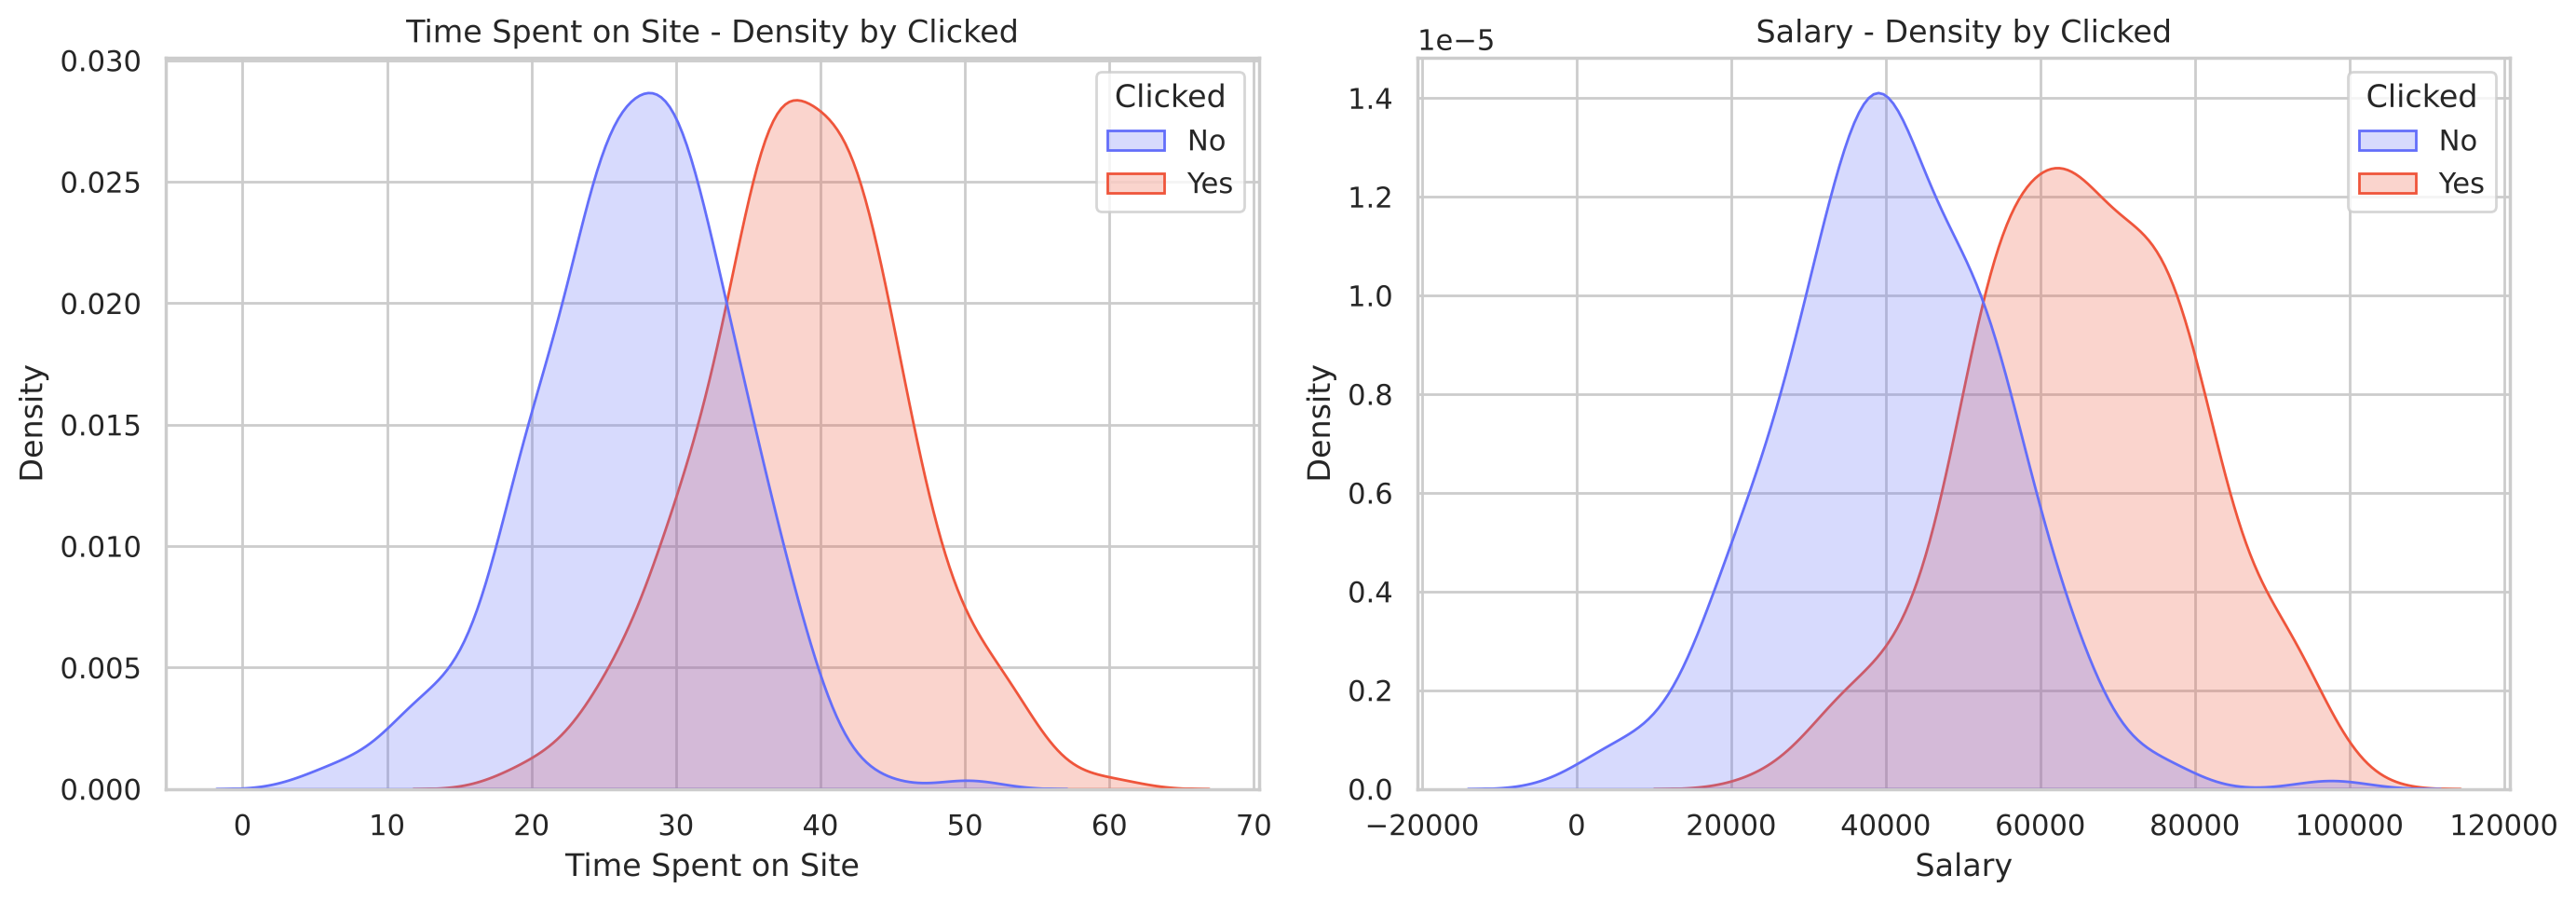

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df_plot, x='Time Spent on Site', hue='Clicked', fill=True, ax=axes[0], palette=color_map)
axes[0].set_title('Time Spent on Site - Density by Clicked')

sns.kdeplot(data=df_plot, x='Salary', hue='Clicked', fill=True, ax=axes[1], palette=color_map)
axes[1].set_title('Salary - Density by Clicked')

plt.tight_layout()
plt.show()

#### 3.4 Relationship between the two features

In [17]:
fig = px.scatter(data_frame=df_plot, x='Time Spent on Site', y='Salary', color='Clicked',
                 color_discrete_map=color_map, opacity=0.8,
                 hover_data=['Names', 'Country'],
                 title='Time Spent on Site vs Salary')
fig.show()

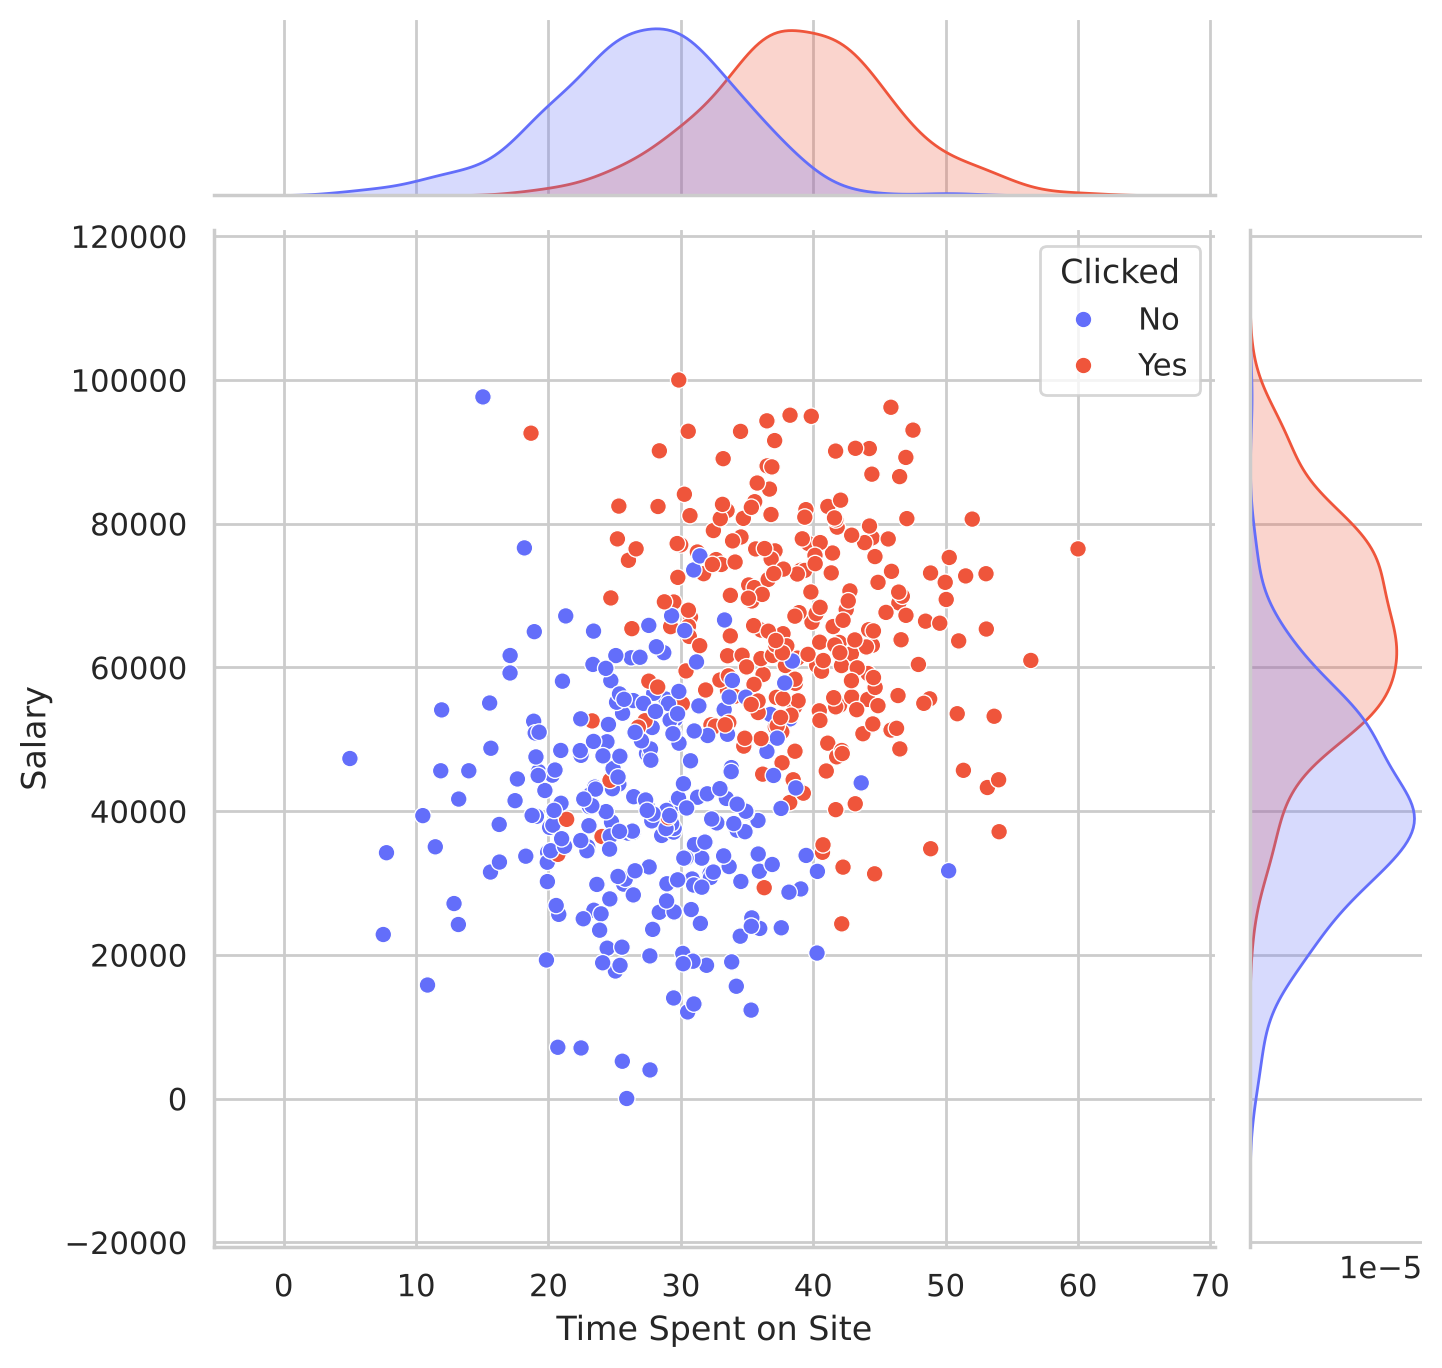

In [18]:
sns.jointplot(data=df_plot, x='Time Spent on Site', y='Salary', hue='Clicked', palette=color_map, height=7)
plt.show()

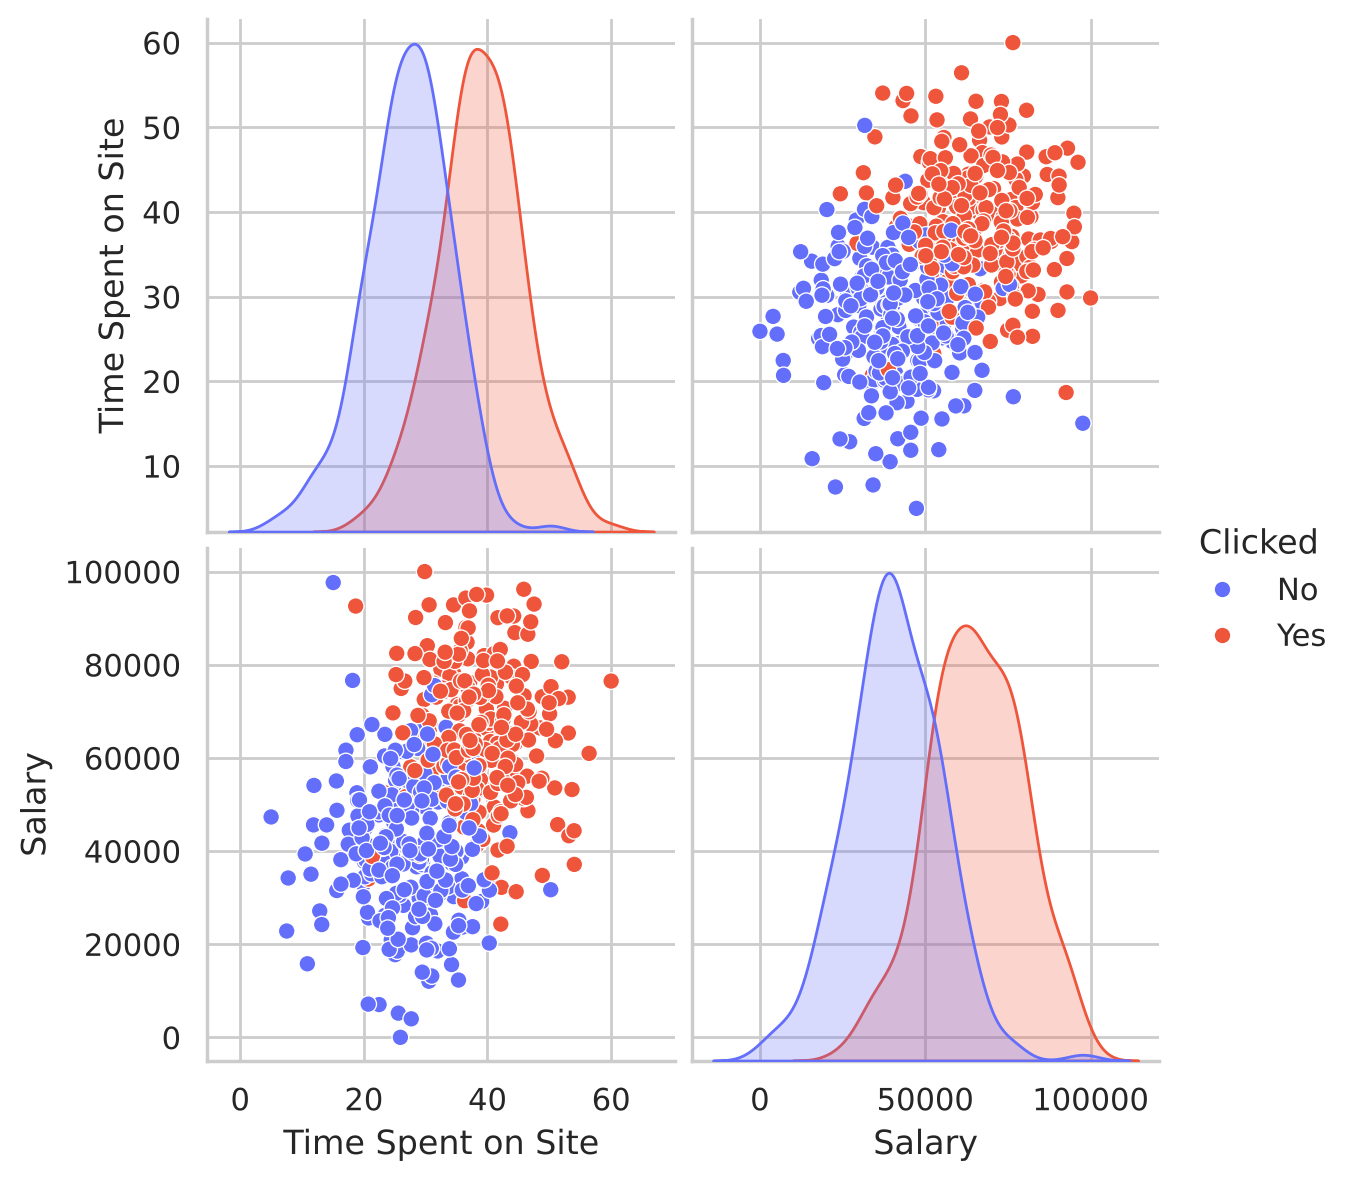

In [19]:
sns.pairplot(df_plot[['Time Spent on Site', 'Salary', 'Clicked']], hue='Clicked', palette=color_map, height=3)
plt.show()

In [20]:
# Correlation only works on numeric columns
corr = df.corr(numeric_only=True)

fig = px.imshow(corr, text_auto='.2f', color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='Correlation Heatmap')
fig.show()

#### 3.5 Country column

In [21]:
print('Number of unique countries:', df['Country'].nunique())
print('Number of rows:', len(df))

Number of unique countries: 210
Number of rows: 499


In [22]:
top_countries = df['Country'].value_counts().head(15)

fig = px.bar(x=top_countries.index, y=top_countries.values,
             labels={'x': 'Country', 'y': 'Number of Users'},
             title='Top 15 Countries by Number of Users')
fig.show()

Almost every country appears only 1 - 5 times, so the `Country` column will not help the model
(too many categories and too few rows per category). We will drop it together with `Names` and `emails`.

## 4. Data preprocessing

In [23]:
df.drop(columns=['Names', 'emails', 'Country'], inplace=True)
df.head()

,Time Spent on Site,Salary,Clicked
0,25.649648,55330.06006,0
1,32.456107,79049.07674,1
2,20.945978,41098.60826,0
3,54.039325,37143.35536,1
4,34.249729,37355.11276,0


In [24]:
X = df.drop('Clicked', axis=1)
y = df['Clicked']

X.head()

,Time Spent on Site,Salary
0,25.649648,55330.06006
1,32.456107,79049.07674
2,20.945978,41098.60826
3,54.039325,37143.35536
4,34.249729,37355.11276


We split **first**, then fit the scaler on the training data only.
This way the test data stays "unseen" (no data leakage).

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)

print('Train shape:', X_train.shape)
print('Test shape :', X_test.shape)

Train shape: (334, 2)
Test shape : (165, 2)


In [26]:
from sklearn.preprocessing import MinMaxScaler

ms = MinMaxScaler()
X_train_scaled = ms.fit_transform(X_train)   # fit + transform on train
X_test_scaled = ms.transform(X_test)         # only transform on test

X_train_scaled[:5]

array([[0.50869555, 0.80707996],
       [0.74320134, 0.51278261],
       [0.58208901, 0.73051855],
       [0.54090387, 0.49042712],
       [0.3862615 , 0.61339434]])

## 5. Model building & training

For every model we do the same 4 steps: **create -> fit -> predict -> accuracy**,
and save the accuracy in the `results` dictionary to compare them at the end.

In [27]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score

results = {}

### 5.1 Logistic Regression

Draws a straight line between the two classes and gives a probability for each user.

**Main parameters:**
- `C` : inverse of regularization strength (small C = simpler model)
- `penalty` : type of regularization (`'l2'` by default)
- `max_iter` : max number of training iterations

In [28]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
results['Logistic Regression'] = accuracy_score(y_test, y_pred_lr)

print('Accuracy:', results['Logistic Regression'])

Accuracy: 0.9333333333333333


### 5.2 KNN (K-Nearest Neighbors)

Looks at the **k** closest users in the training data and takes the majority vote.

**Main parameters:**
- `n_neighbors` : number of neighbors (k)
- `weights` : `'uniform'` (all neighbors equal) or `'distance'` (closer = stronger)
- `metric` : how distance is measured (`'minkowski'` = Euclidean by default)

First we search for the best **k** using 5-fold cross-validation on the training data.

In [29]:
from sklearn.neighbors import KNeighborsClassifier

k_values = range(1, 31)
k_scores = []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn_temp, X_train_scaled, y_train, cv=5).mean()
    k_scores.append(score)

best_k = k_values[np.argmax(k_scores)]
print('Best k:', best_k)

Best k: 21


In [30]:
fig = px.line(x=list(k_values), y=k_scores, markers=True,
              labels={'x': 'k (n_neighbors)', 'y': 'Cross-Validation Accuracy'},
              title='KNN - Choosing the Best k')
fig.add_vline(x=best_k, line_dash='dash', line_color='red')
fig.show()

In [31]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
results['KNN'] = accuracy_score(y_test, y_pred_knn)

print('Accuracy:', results['KNN'])

Accuracy: 0.9333333333333333


### 5.3 Decision Tree

Asks yes/no questions like "Salary > 50,000?" and splits the data step by step.

**Main parameters:**
- `max_depth` : max number of questions from top to bottom (controls overfitting)
- `min_samples_split` : min rows needed to split a node
- `criterion` : how to measure a good split (`'gini'` or `'entropy'`)

Let's see how `max_depth` affects train accuracy vs cross-validation accuracy (overfitting).

In [32]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

depths = range(1, 16)
train_scores = []
cv_scores = []

for d in depths:
    tree_temp = DecisionTreeClassifier(max_depth=d, random_state=42)
    tree_temp.fit(X_train_scaled, y_train)
    train_scores.append(tree_temp.score(X_train_scaled, y_train))
    cv_scores.append(cross_val_score(tree_temp, X_train_scaled, y_train, cv=5).mean())

best_depth = depths[np.argmax(cv_scores)]
print('Best max_depth:', best_depth)

Best max_depth: 2


In [33]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=list(depths), y=train_scores, mode='lines+markers', name='Train Accuracy'))
fig.add_trace(go.Scatter(x=list(depths), y=cv_scores, mode='lines+markers', name='Cross-Validation Accuracy'))
fig.add_vline(x=best_depth, line_dash='dash', line_color='red')
fig.update_layout(title='Decision Tree - Overfitting Check', xaxis_title='max_depth', yaxis_title='Accuracy')
fig.show()

In [34]:
dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt.fit(X_train_scaled, y_train)

y_pred_dt = dt.predict(X_test_scaled)
results['Decision Tree'] = accuracy_score(y_test, y_pred_dt)

print('Accuracy:', results['Decision Tree'])

Accuracy: 0.8666666666666667


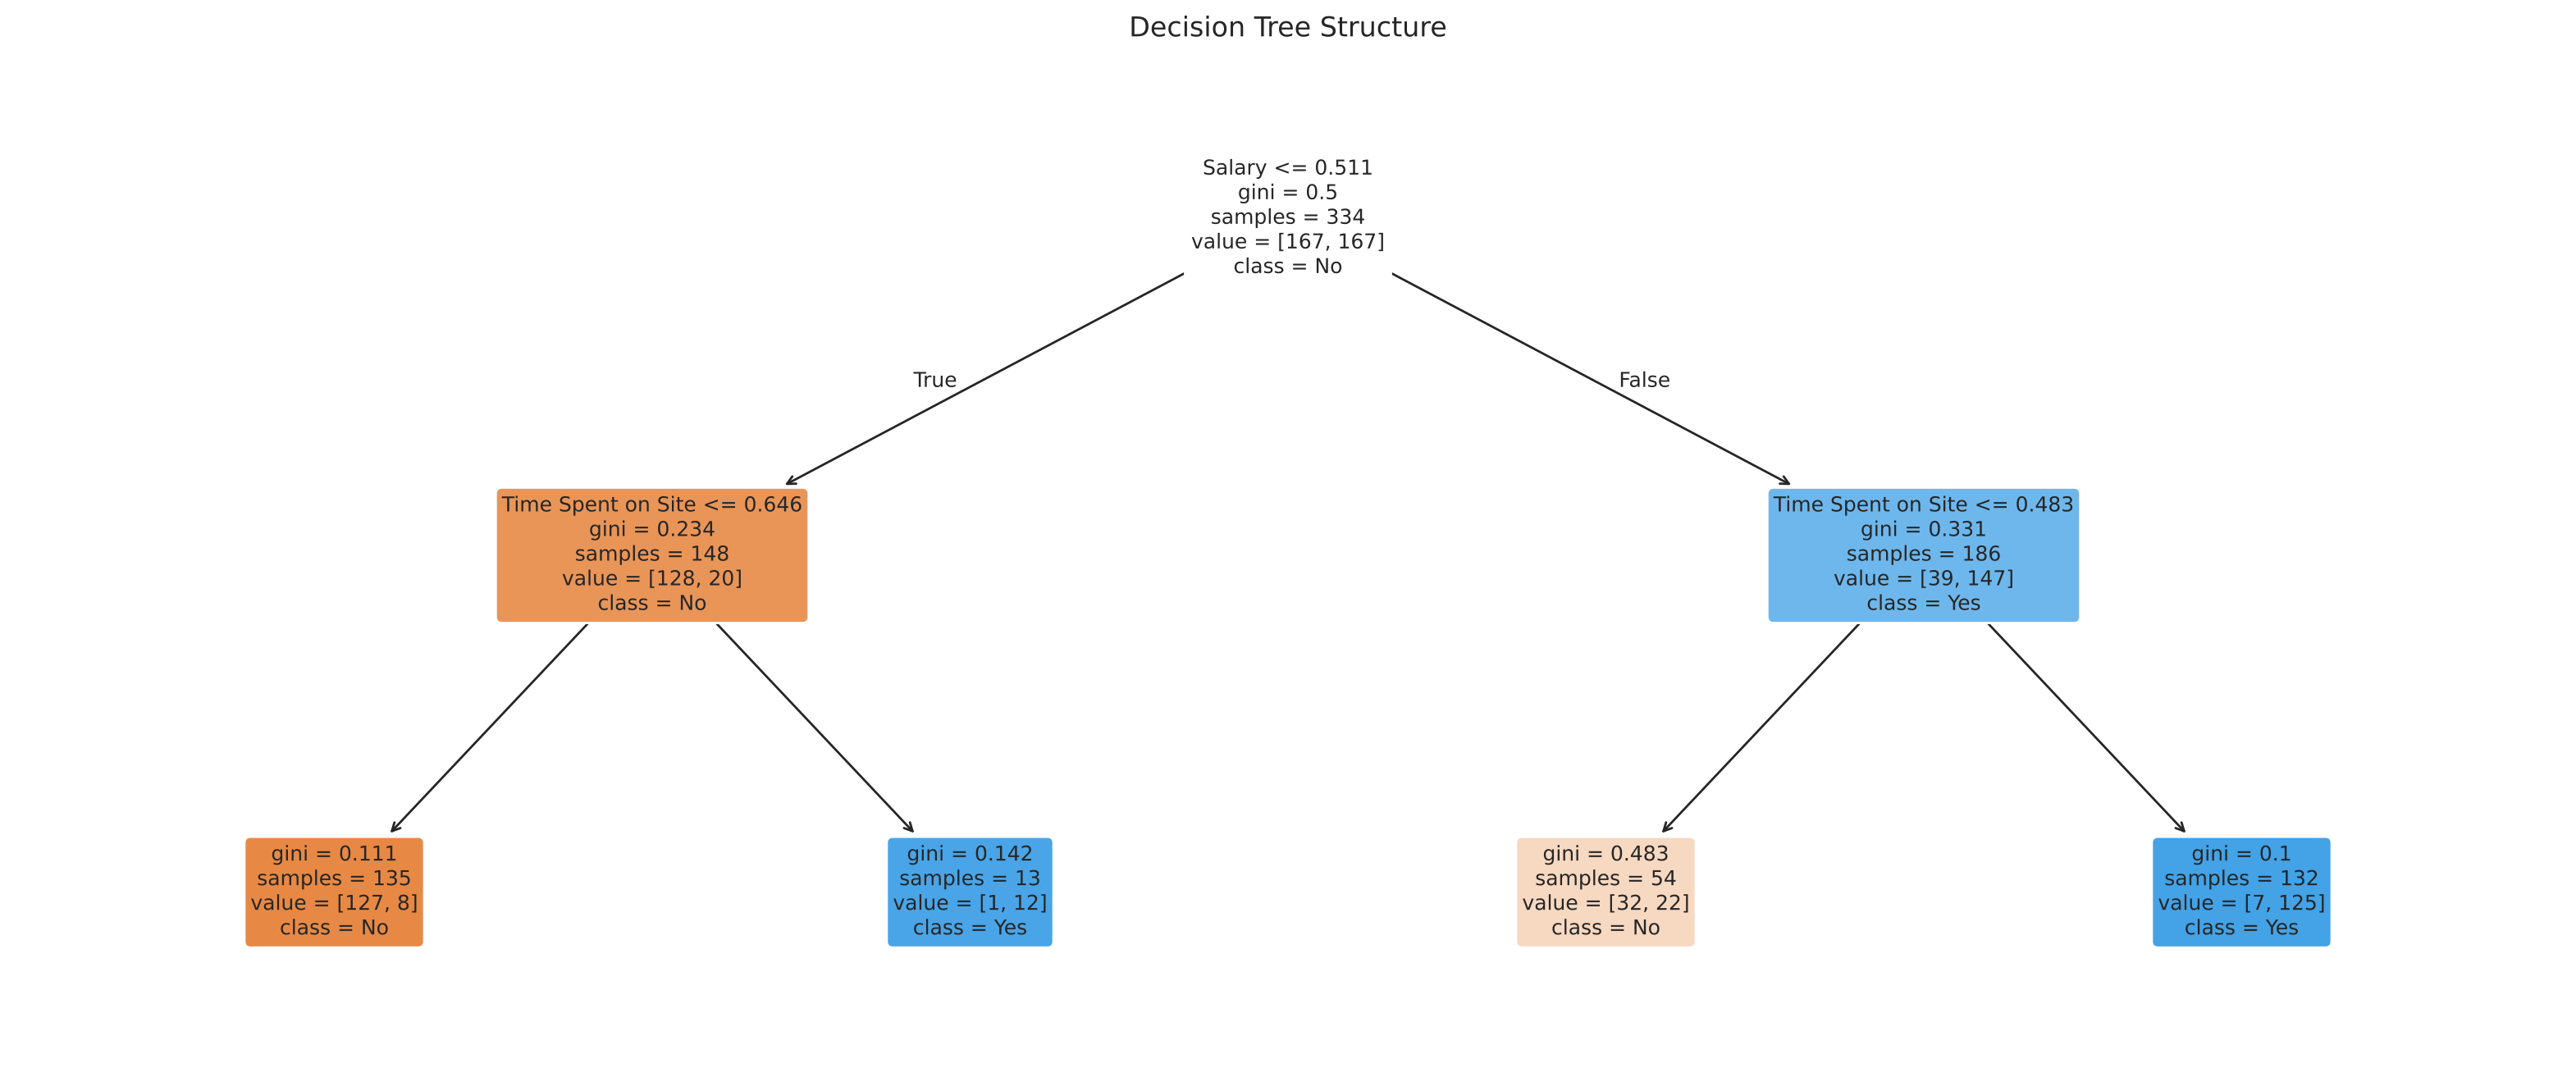

In [35]:
plt.figure(figsize=(20, 8))
plot_tree(dt, feature_names=list(X.columns), class_names=['No', 'Yes'], filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Structure')
plt.show()

### 5.4 Random Forest

Builds many decision trees on random parts of the data, then takes the majority vote.

**Main parameters:**
- `n_estimators` : number of trees
- `max_depth` : max depth of each tree
- `max_features` : number of features each tree looks at when splitting

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
results['Random Forest'] = accuracy_score(y_test, y_pred_rf)

print('Accuracy:', results['Random Forest'])

Accuracy: 0.9212121212121213


In [37]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

fig = px.bar(x=importance.values, y=importance.index, orientation='h',
             labels={'x': 'Importance', 'y': 'Feature'},
             title='Random Forest - Feature Importance')
fig.show()

### 5.5 SVM (Support Vector Machine)

Finds the boundary with the **widest margin** between the two classes. With `kernel='rbf'` the boundary can be curved.

**Main parameters:**
- `C` : penalty for misclassified points (big C = tighter fit)
- `kernel` : shape of the boundary (`'linear'`, `'rbf'`, `'poly'`)
- `gamma` : how far the influence of one point reaches (for `'rbf'`)
- `probability=True` : lets the model give probabilities (needed for the app)

In [38]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', C=1, probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)

y_pred_svm = svm.predict(X_test_scaled)
results['SVM'] = accuracy_score(y_test, y_pred_svm)

print('Accuracy:', results['SVM'])

Accuracy: 0.9393939393939394


### 5.6 Naive Bayes

Uses probabilities (Bayes' theorem) and assumes each feature follows a normal (bell) curve inside each class.

**Main parameters:**
- `var_smoothing` : small value added to variances for stability

In [39]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

y_pred_nb = nb.predict(X_test_scaled)
results['Naive Bayes'] = accuracy_score(y_test, y_pred_nb)

print('Accuracy:', results['Naive Bayes'])

Accuracy: 0.9393939393939394


## 6. Model comparison

In [40]:
models = {
    'Logistic Regression': lr,
    'KNN': knn,
    'Decision Tree': dt,
    'Random Forest': rf,
    'SVM': svm,
    'Naive Bayes': nb,
}

In [41]:
# Cross-validation accuracy on the training data = more stable view of each model
cv_results = {}
for name, model in models.items():
    cv_results[name] = cross_val_score(model, X_train_scaled, y_train, cv=5).mean()

results_df = pd.DataFrame({
    'Test Accuracy': results,
    'CV Accuracy': cv_results,
}).round(4)

# Sort by test accuracy; if two models tie, the higher CV accuracy wins
results_df = results_df.sort_values(['Test Accuracy', 'CV Accuracy'], ascending=False)

results_df

,Test Accuracy,CV Accuracy
Naive Bayes,0.9394,0.8892
SVM,0.9394,0.8772
Logistic Regression,0.9333,0.8922
KNN,0.9333,0.8921
Random Forest,0.9212,0.8922
Decision Tree,0.8667,0.8682


In [42]:
fig = px.bar(results_df.reset_index(), x='index', y=['Test Accuracy', 'CV Accuracy'], barmode='group',
             text_auto='.3f', labels={'index': 'Model', 'value': 'Accuracy', 'variable': 'Metric'},
             title='Model Comparison - Accuracy')
fig.update_yaxes(range=[0.7, 1])
fig.show()

#### 6.1 Confusion matrix for every model

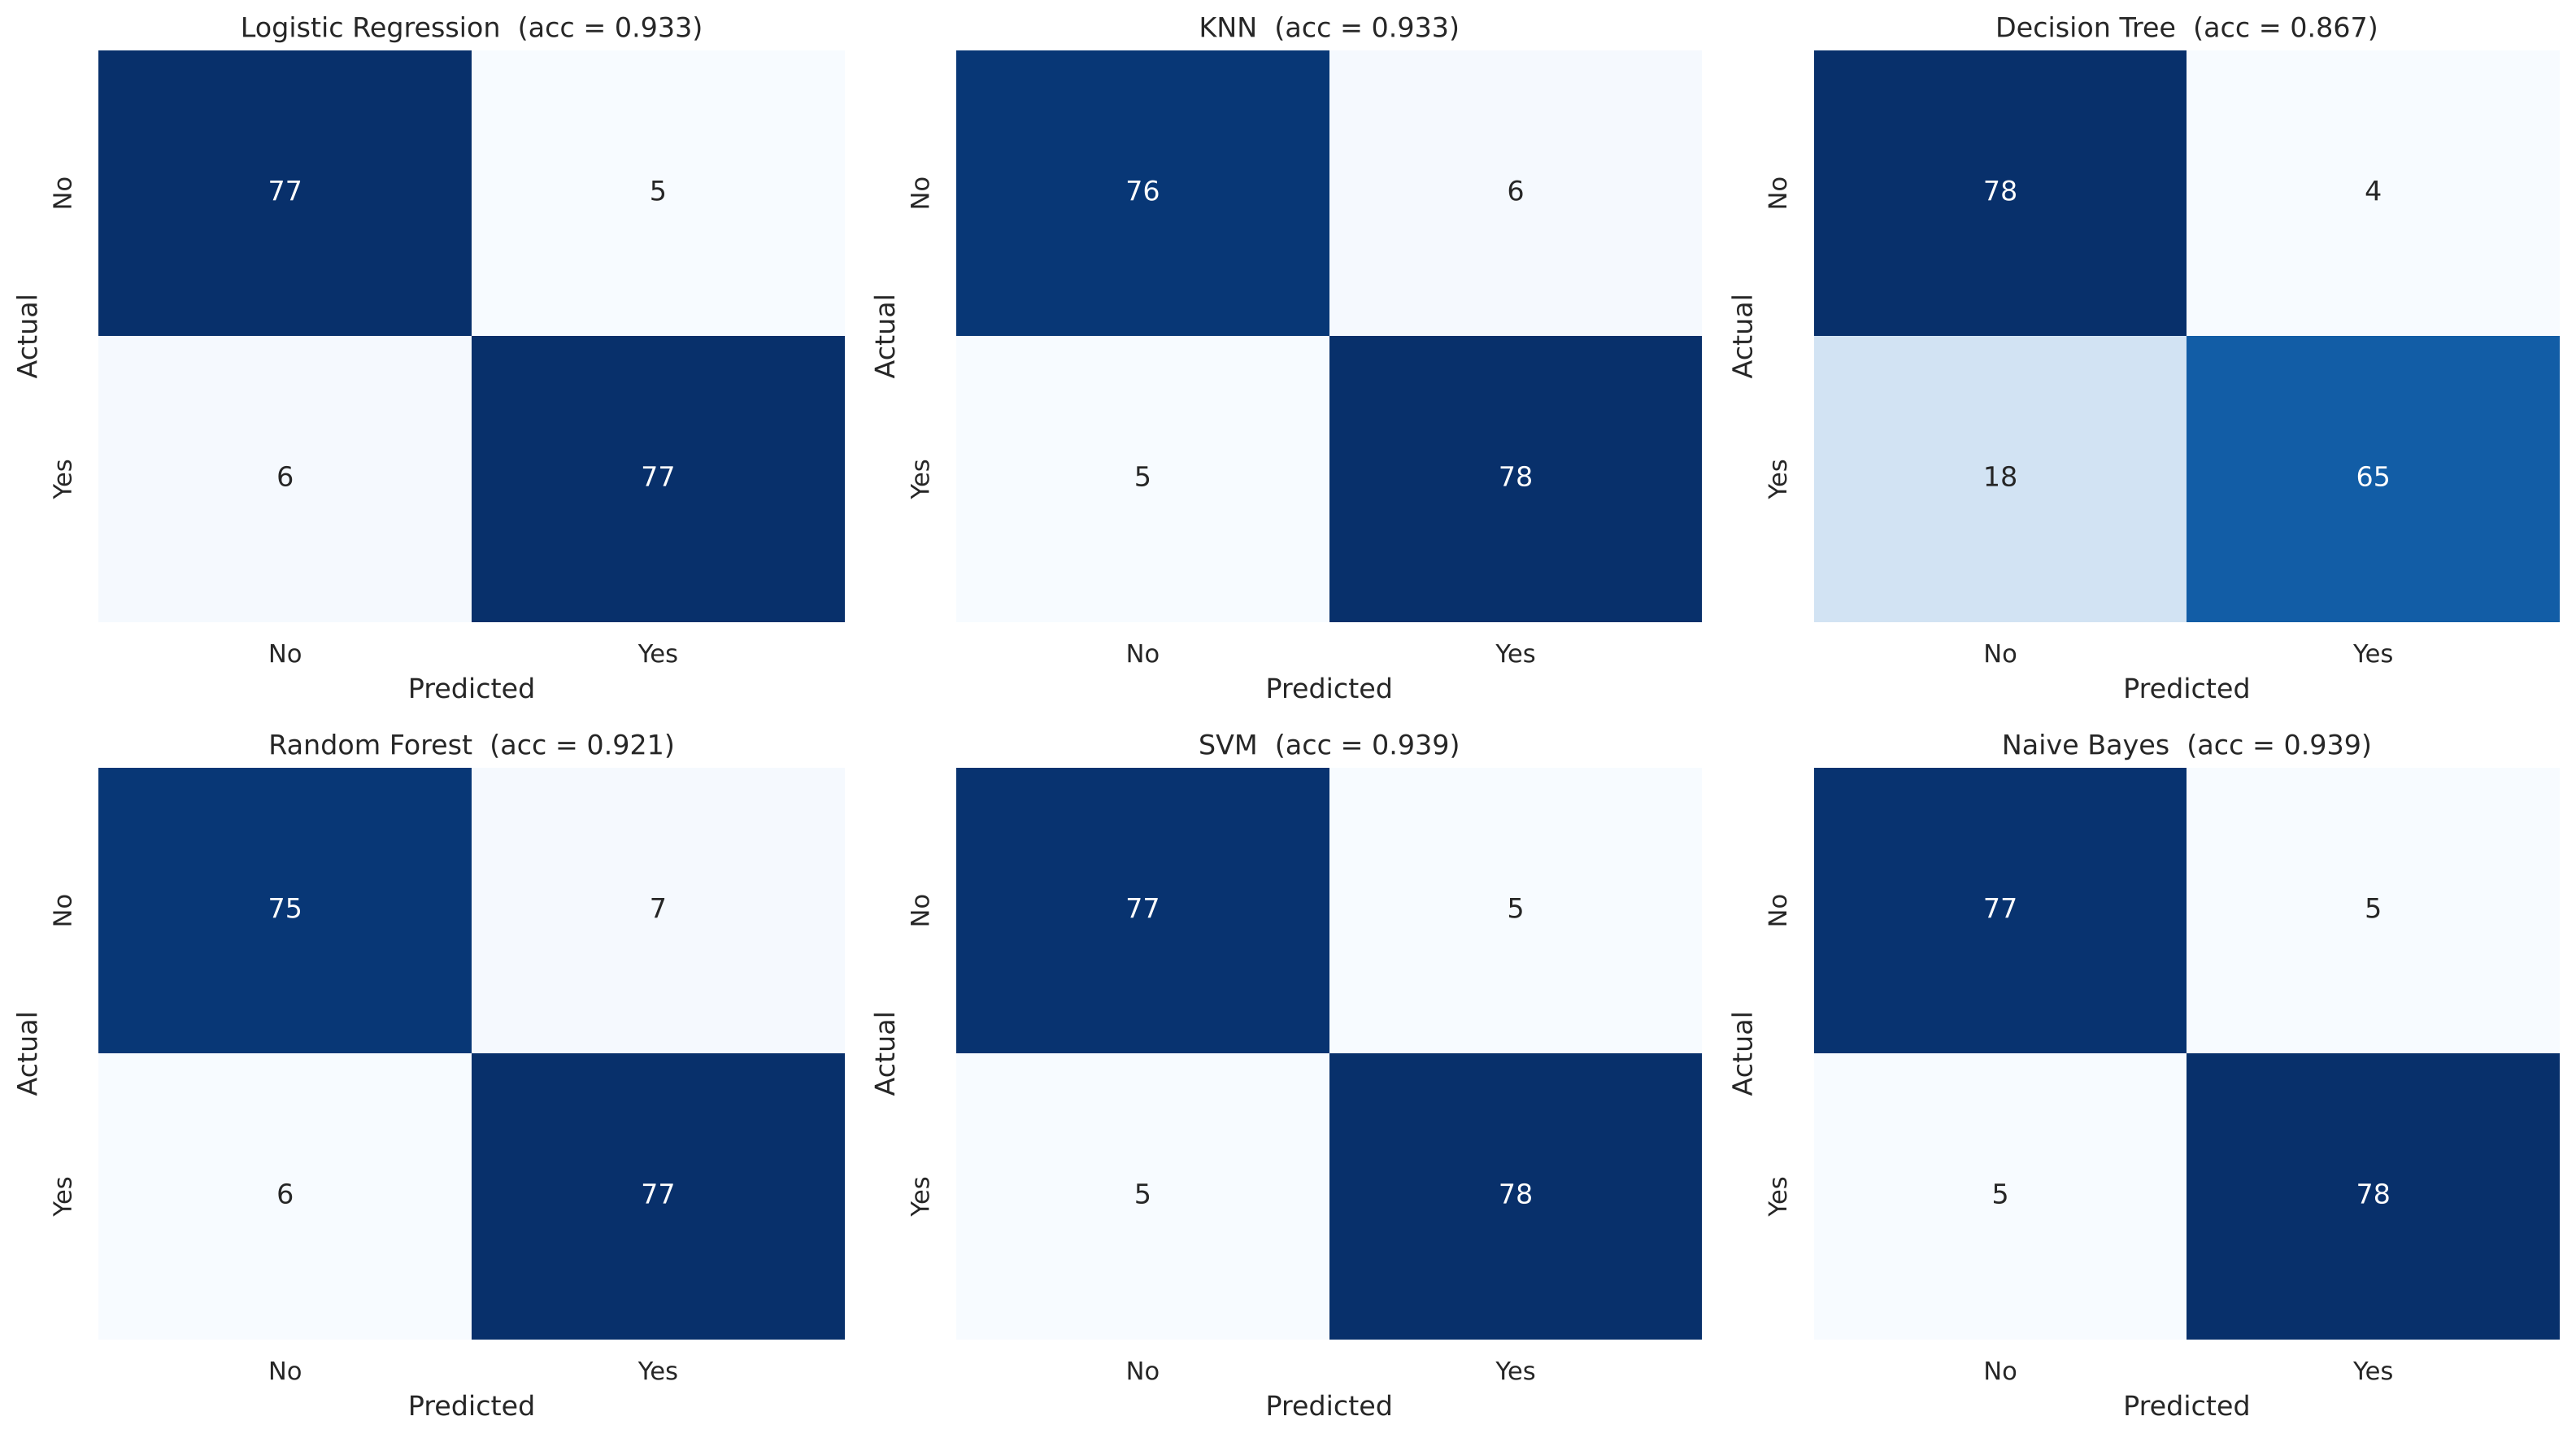

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (name, model) in zip(axes.flatten(), models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_scaled))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    ax.set_title(f'{name}  (acc = {results[name]:.3f})')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

#### 6.2 ROC (Receiver Operating Characteristic) curve for every model

In [44]:
from sklearn.metrics import roc_curve, roc_auc_score

fig = go.Figure()
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode='lines', name=f'{name} (AUC = {auc:.3f})'))

fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode='lines', name='Random Guess', line=dict(dash='dash', color='gray')))
fig.update_layout(title='ROC Curves', xaxis_title='False Positive Rate', yaxis_title='True Positive Rate',
                  width=800, height=600)
fig.show()

#### 6.3 Decision boundaries

Because we only have 2 features, we can **see** how each model splits the data.
Blue area = model says "No click", red area = model says "Click".

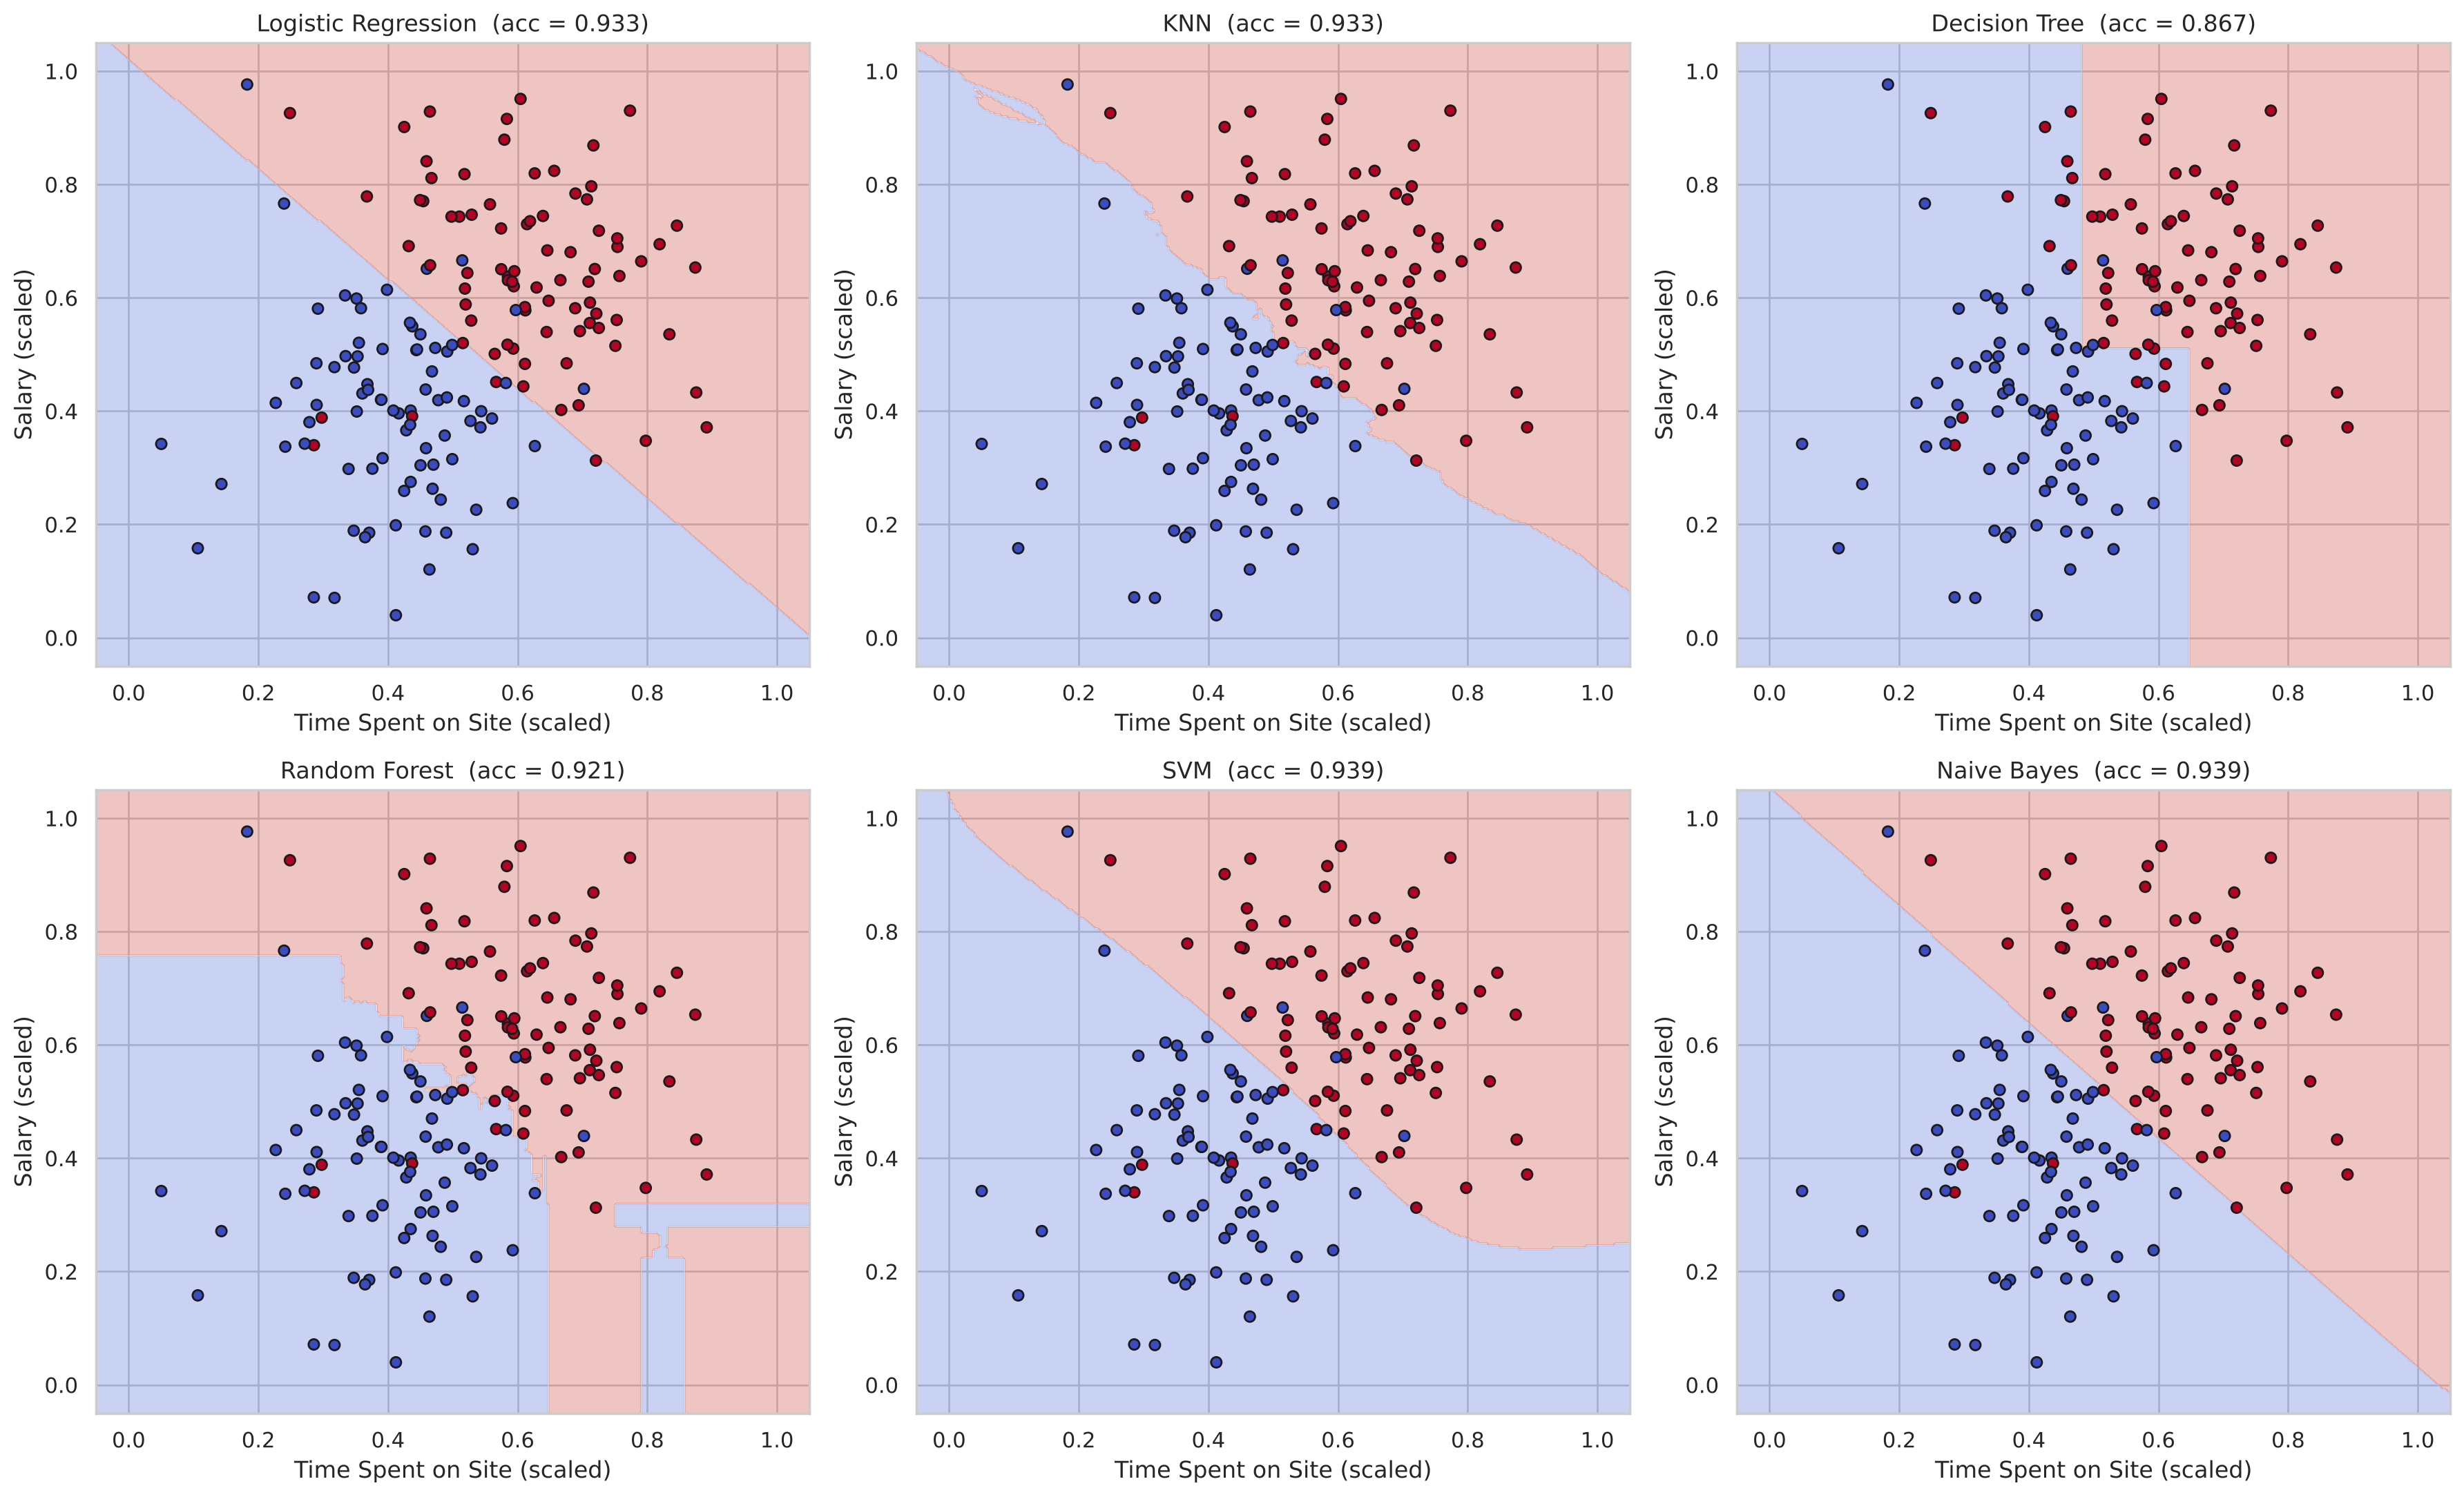

In [45]:
# Grid of points covering the scaled feature space (0 -> 1)
xx, yy = np.meshgrid(np.linspace(-0.05, 1.05, 300), np.linspace(-0.05, 1.05, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

for ax, (name, model) in zip(axes.flatten(), models.items()):
    Z = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_test_scaled[:, 0], X_test_scaled[:, 1], c=y_test, cmap='coolwarm', edgecolor='k', s=30)
    ax.set_title(f'{name}  (acc = {results[name]:.3f})')
    ax.set_xlabel('Time Spent on Site (scaled)')
    ax.set_ylabel('Salary (scaled)')

plt.tight_layout()
plt.show()

#### 6.4 The best model

In [46]:
best_name = results_df.index[0]
best_model = models[best_name]

print('Best model:', best_name)
print('Test accuracy:', results_df.loc[best_name, 'Test Accuracy'])

Best model: Naive Bayes
Test accuracy: 0.9394


In [47]:
y_pred_best = best_model.predict(X_test_scaled)
print(classification_report(y_test, y_pred_best, target_names=['No', 'Yes']))

              precision    recall  f1-score   support

          No       0.94      0.94      0.94        82
         Yes       0.94      0.94      0.94        83

    accuracy                           0.94       165
   macro avg       0.94      0.94      0.94       165
weighted avg       0.94      0.94      0.94       165



## 7. Saving the model with pickle

The Streamlit app needs **both** the model and the scaler
(new user data must be scaled the same way as the training data).

Files we save:
- `best_model.pkl` : the best model
- `scaler.pkl` : the fitted MinMaxScaler
- `all_models.pkl` : all 6 trained models (so the app can compare them)
- `model_results.csv` : the accuracy table

In [48]:
import pickle

with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(ms, f)

with open('all_models.pkl', 'wb') as f:
    pickle.dump(models, f)

results_df.to_csv('model_results.csv', index_label='Model')

print('Saved!')

Saved!


### Test: load the saved files and predict a new user

In [49]:
with open('best_model.pkl', 'rb') as f:
    model = pickle.load(f)

with open('scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

new_user = pd.DataFrame([[25, 55000]], columns=['Time Spent on Site', 'Salary'])
new_user_scaled = scaler.transform(new_user)

print('Prediction :', model.predict(new_user_scaled)[0])
print('Probability of click:', round(model.predict_proba(new_user_scaled)[0][1], 3))

Prediction : 0
Probability of click: 0.148


### Next step

Put `app.py`, `facebook_ads.csv` and the 4 saved files in the same folder, then run:

```
streamlit run app.py
```

---

# THANK YOU!